<a href="https://colab.research.google.com/github/IvanovaKaryna/123/blob/main/%D0%9B%D0%A013_%D0%86%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Класифікація зображень гральних карт

**ПІБ студента:** Іванова Карина

**Група:** ФІТ 3-10

**Дата:** 24.11.2026

Набір даних: [Cards Image Dataset-Classification](https://www.kaggle.com/datasets/gpiosenka/cards-image-datasetclassification) (53 класи, зображення 224x224).

У роботі я реалізую власну згорткову модель та донавчаю модель VGG16, а потім порівняю результати.

Для швидшого навчання в Colab зображення зменшено до 128x128, а кількість епох невелика.

## Частина 1. Підготовка та аналіз даних

### 1. Імпорт бібліотек

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

tf.random.set_seed(42)
np.random.seed(42)

print('Бібліотеки імпортовано')
print('Версія TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

Бібліотеки імпортовано
Версія TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 2. Завантаження даних

In [2]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download('gpiosenka/cards-image-datasetclassification')
print(path)
print(os.listdir(path))

100%|██████████| 385M/385M [00:10<00:00, 37.6MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/gpiosenka/cards-image-datasetclassification/versions/2
['valid', '53cards-53-(200 X 200)-100.00.h5', 'test', 'train', 'cards.csv', '14card types-14-(200 X 200)-94.61.h5']


In [3]:
base_dir = path
img_size = (128, 128)
batch_size = 32

train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(base_dir, 'train'),
    image_size=img_size,
    batch_size=batch_size,
    label_mode='int',
    shuffle=True,
    seed=42
)

val_ds = keras.utils.image_dataset_from_directory(
    os.path.join(base_dir, 'valid'),
    image_size=img_size,
    batch_size=batch_size,
    label_mode='int',
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    os.path.join(base_dir, 'test'),
    image_size=img_size,
    batch_size=batch_size,
    label_mode='int',
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print('Кількість класів:', num_classes)
print(class_names)

Found 7624 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Кількість класів: 53
['ace of clubs', 'ace of diamonds', 'ace of hearts', 'ace of spades', 'eight of clubs', 'eight of diamonds', 'eight of hearts', 'eight of spades', 'five of clubs', 'five of diamonds', 'five of hearts', 'five of spades', 'four of clubs', 'four of diamonds', 'four of hearts', 'four of spades', 'jack of clubs', 'jack of diamonds', 'jack of hearts', 'jack of spades', 'joker', 'king of clubs', 'king of diamonds', 'king of hearts', 'king of spades', 'nine of clubs', 'nine of diamonds', 'nine of hearts', 'nine of spades', 'queen of clubs', 'queen of diamonds', 'queen of hearts', 'queen of spades', 'seven of clubs', 'seven of diamonds', 'seven of hearts', 'seven of spades', 'six of clubs', 'six of diamonds', 'six of hearts', 'six of spades', 'ten of clubs', 'ten of diamonds', 'ten of hearts', 'ten of spades', 'three of clubs', 'three of diamonds', 'th

### 3. Виведення даних

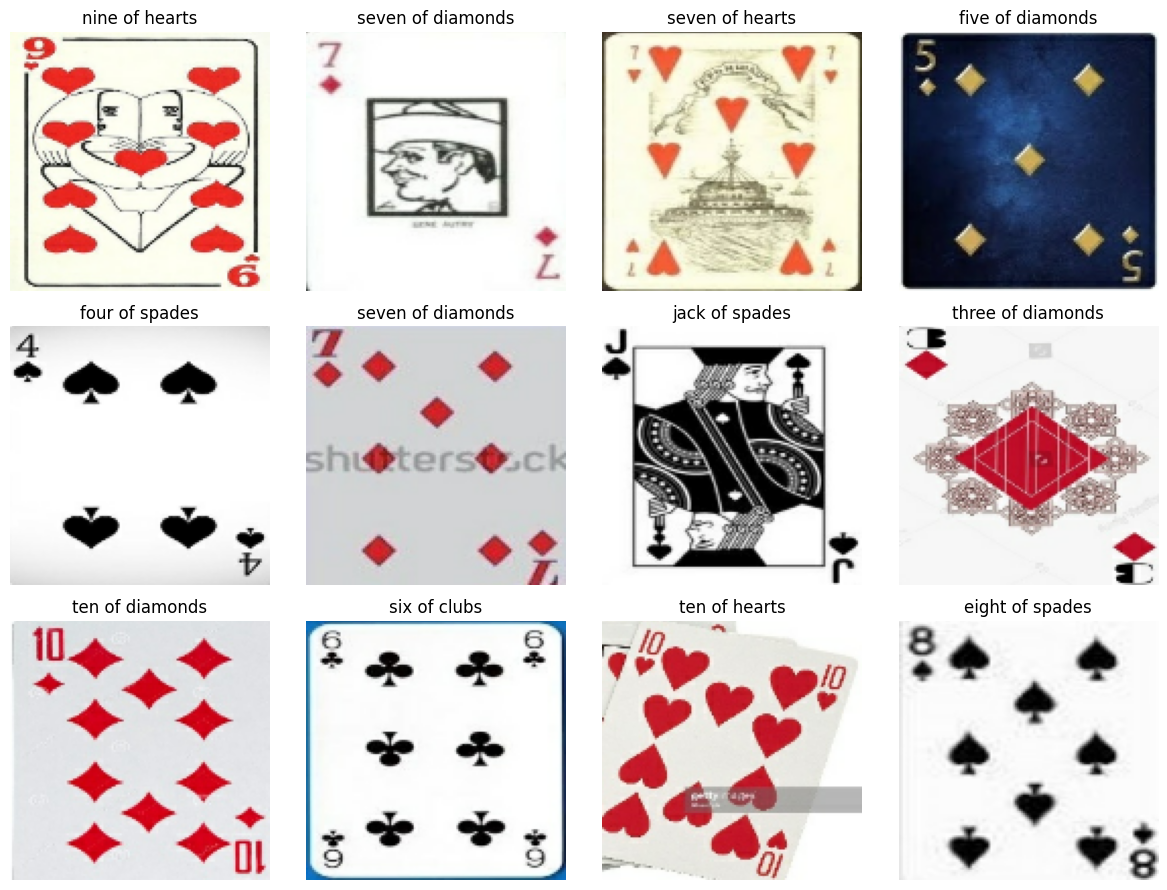

In [4]:
plt.figure(figsize=(12, 9))
for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]])
        plt.axis('off')
plt.tight_layout()
plt.show()

### 4. Аналіз даних

Розмір батчу зображень: (32, 128, 128, 3)
Розмір батчу міток: (32,)
Мінімум і максимум пікселів: 0.0 255.0
count     53.000000
mean     143.849057
std       17.386330
min      108.000000
25%      129.000000
50%      142.000000
75%      158.000000
max      181.000000
dtype: float64


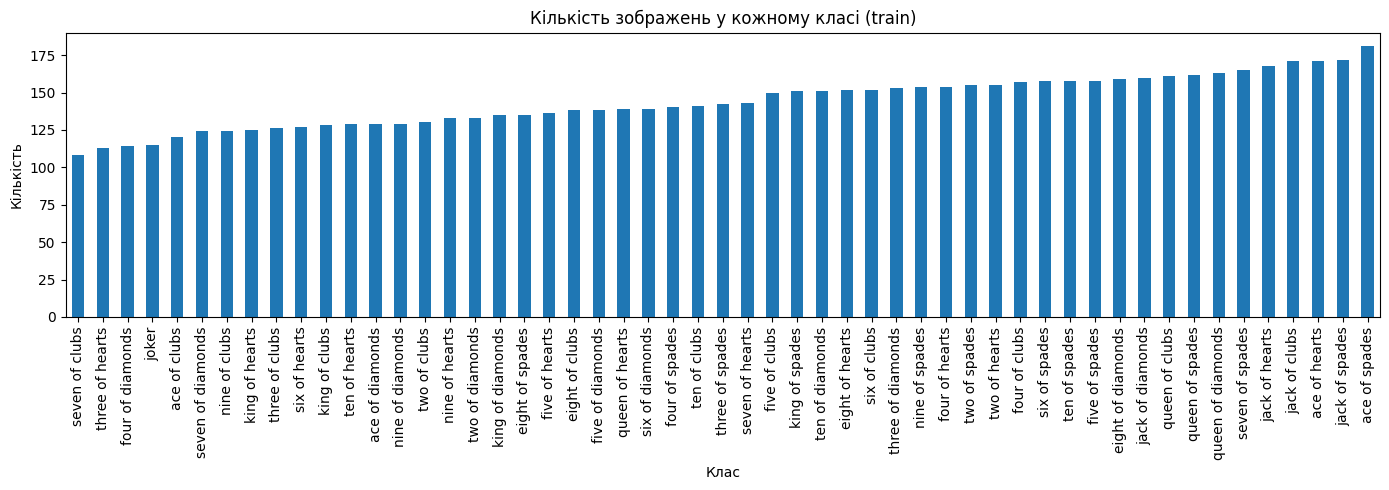

train: 7624
valid: 265
test: 265


In [5]:
for images, labels in train_ds.take(1):
    print('Розмір батчу зображень:', images.shape)
    print('Розмір батчу міток:', labels.shape)
    print('Мінімум і максимум пікселів:', images.numpy().min(), images.numpy().max())

counts = {}
for c in class_names:
    counts[c] = len(os.listdir(os.path.join(base_dir, 'train', c)))

counts = pd.Series(counts).sort_values()
print(counts.describe())

plt.figure(figsize=(14, 5))
counts.plot(kind='bar')
plt.title('Кількість зображень у кожному класі (train)')
plt.xlabel('Клас')
plt.ylabel('Кількість')
plt.tight_layout()
plt.show()

print('train:', sum(counts))
print('valid:', sum(len(os.listdir(os.path.join(base_dir, 'valid', c))) for c in class_names))
print('test:', sum(len(os.listdir(os.path.join(base_dir, 'test', c))) for c in class_names))

**Висновок за аналізом:** усі зображення мають однаковий розмір (оригінал 224x224, для швидкості зменшено до 128x128) із трьома каналами, значення пікселів від 0 до 255. Класи майже збалансовані (у деяких карт зображень трохи менше), тому дисбаланс не критичний. Валідаційна і тестова вибірки невеликі (по 5 зображень на клас).

### 5. Підготовка даних

In [6]:
augment = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

## Частина 2. Власна згорткова модель

### 6. Побудова згорткової моделі

In [7]:
def build_cnn(lr=1e-3, dropout=0.4):
    model = keras.Sequential([
        layers.Input(shape=img_size + (3,)),
        augment,
        layers.Rescaling(1.0 / 255),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(256, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout),
        layers.Dense(256, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(num_classes, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

build_cnn().summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 53)             │        13,621 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 469,749 (1.79 MB)

 Trainable params: 468,789 (1.79 MB)

 Non-trainable params: 960 (3.75 KB)

### 7. Підбір параметрів для згорткової моделі

In [8]:
cnn_results = []

for lr in [1e-3, 3e-4]:
    for dr in [0.3, 0.5]:
        keras.backend.clear_session()
        model = build_cnn(lr, dr)
        h = model.fit(train_ds, validation_data=val_ds, epochs=2, verbose=2)
        acc = max(h.history['val_accuracy'])
        cnn_results.append((lr, dr, acc))
        print('lr =', lr, ' dropout =', dr, ' val_accuracy =', round(acc, 4))

best_cnn = max(cnn_results, key=lambda x: x[2])
print('Найкращі параметри (lr, dropout, val_accuracy):', best_cnn)

Epoch 1/2
239/239 - 23s - 98ms/step - accuracy: 0.0790 - loss: 3.4921 - val_accuracy: 0.0340 - val_loss: 6.5829
Epoch 2/2
239/239 - 11s - 47ms/step - accuracy: 0.1304 - loss: 3.0392 - val_accuracy: 0.0453 - val_loss: 3.9210
lr = 0.001  dropout = 0.3  val_accuracy = 0.0453
Epoch 1/2
239/239 - 16s - 65ms/step - accuracy: 0.0552 - loss: 3.7994 - val_accuracy: 0.0189 - val_loss: 7.0781
Epoch 2/2
239/239 - 20s - 85ms/step - accuracy: 0.0838 - loss: 3.3079 - val_accuracy: 0.0453 - val_loss: 3.9452
lr = 0.001  dropout = 0.5  val_accuracy = 0.0453
Epoch 1/2
239/239 - 16s - 68ms/step - accuracy: 0.0732 - loss: 3.6474 - val_accuracy: 0.0340 - val_loss: 4.8689
Epoch 2/2
239/239 - 20s - 83ms/step - accuracy: 0.1083 - loss: 3.2494 - val_accuracy: 0.1019 - val_loss: 3.1698
lr = 0.0003  dropout = 0.3  val_accuracy = 0.1019
Epoch 1/2
239/239 - 15s - 62ms/step - accuracy: 0.0496 - loss: 4.0231 - val_accuracy: 0.0189 - val_loss: 4.6411
Epoch 2/2
239/239 - 11s - 47ms/step - accuracy: 0.0740 - loss: 3.542

### 8. Навчання згорткової моделі з ранньою зупинкою

In [9]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

keras.backend.clear_session()
cnn_model = build_cnn(best_cnn[0], best_cnn[1])

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop],
    verbose=2
)

Epoch 1/15
239/239 - 16s - 66ms/step - accuracy: 0.0674 - loss: 3.6229 - val_accuracy: 0.0189 - val_loss: 5.2159
Epoch 2/15
239/239 - 20s - 82ms/step - accuracy: 0.1082 - loss: 3.2113 - val_accuracy: 0.0717 - val_loss: 3.2425
Epoch 3/15
239/239 - 12s - 48ms/step - accuracy: 0.1432 - loss: 3.0046 - val_accuracy: 0.1736 - val_loss: 2.7499
Epoch 4/15
239/239 - 11s - 48ms/step - accuracy: 0.1826 - loss: 2.8304 - val_accuracy: 0.2906 - val_loss: 2.4055
Epoch 5/15
239/239 - 11s - 47ms/step - accuracy: 0.2278 - loss: 2.6347 - val_accuracy: 0.3434 - val_loss: 2.2201
Epoch 6/15
239/239 - 11s - 48ms/step - accuracy: 0.2695 - loss: 2.4712 - val_accuracy: 0.3623 - val_loss: 2.1071
Epoch 7/15
239/239 - 11s - 47ms/step - accuracy: 0.3170 - loss: 2.3128 - val_accuracy: 0.4717 - val_loss: 1.8416
Epoch 8/15
239/239 - 11s - 48ms/step - accuracy: 0.3532 - loss: 2.1877 - val_accuracy: 0.4679 - val_loss: 1.9029
Epoch 9/15
239/239 - 12s - 48ms/step - accuracy: 0.3889 - loss: 2.0500 - val_accuracy: 0.4717 - 

### 9. Криві навчання згорткової моделі

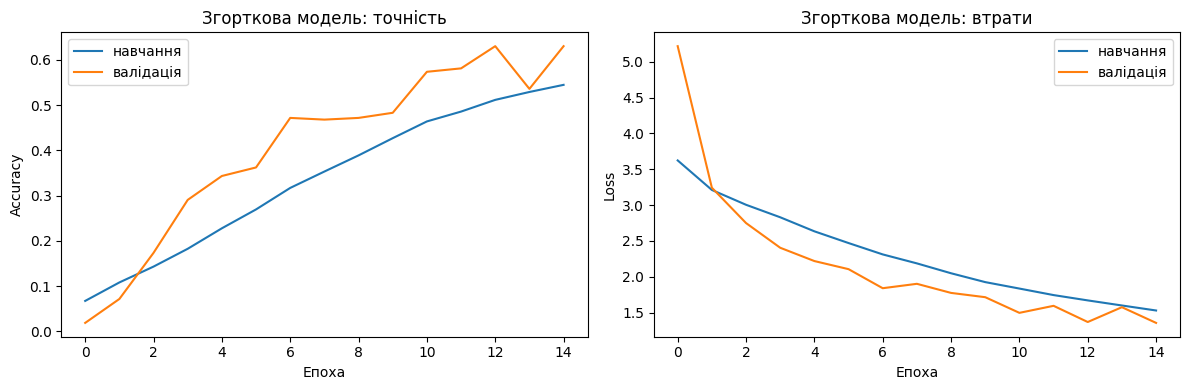

In [10]:
def plot_history(history, title):
    if not isinstance(history, dict):
        history = history.history
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history['accuracy'], label='навчання')
    plt.plot(history['val_accuracy'], label='валідація')
    plt.title(title + ': точність')
    plt.xlabel('Епоха')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['loss'], label='навчання')
    plt.plot(history['val_loss'], label='валідація')
    plt.title(title + ': втрати')
    plt.xlabel('Епоха')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(cnn_history, 'Згорткова модель')

## Частина 3. Модель VGG16 (донавчання)

### 10. Побудова моделі на основі VGG16

In [11]:
def build_vgg(lr=1e-3, dropout=0.4, units=256):
    base = VGG16(weights='imagenet', include_top=False, input_shape=img_size + (3,))
    base.trainable = False

    inputs = keras.Input(shape=img_size + (3,))
    x = augment(inputs)
    x = layers.Lambda(preprocess_input)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(units, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base

### 11. Підбір параметрів для VGG16

In [12]:
vgg_results = []

for lr in [1e-3, 1e-4]:
    for units in [128, 256]:
        keras.backend.clear_session()
        model, base = build_vgg(lr, 0.4, units)
        h = model.fit(train_ds, validation_data=val_ds, epochs=2, verbose=2)
        acc = max(h.history['val_accuracy'])
        vgg_results.append((lr, units, acc))
        print('lr =', lr, ' units =', units, ' val_accuracy =', round(acc, 4))

best_vgg = max(vgg_results, key=lambda x: x[2])
print('Найкращі параметри (lr, units, val_accuracy):', best_vgg)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/2
239/239 - 18s - 74ms/step - accuracy: 0.0556 - loss: 4.4559 - val_accuracy: 0.1396 - val_loss: 3.4076
Epoch 2/2
239/239 - 11s - 47ms/step - accuracy: 0.1253 - loss: 3.3556 - val_accuracy: 0.1774 - val_loss: 2.7509
lr = 0.001  units = 128  val_accuracy = 0.1774
Epoch 1/2
239/239 - 13s - 55ms/step - accuracy: 0.1023 - loss: 4.4576 - val_accuracy: 0.2340 - val_loss: 2.8236
Epoch 2/2
239/239 - 20s - 84ms/step - accuracy: 0.2079 - loss: 2.8882 - val_accuracy: 0.2868 - val_loss: 2.3219
lr = 0.001  units = 256  val_accuracy = 0.2868
Epoch 1/2
239/239 - 14s - 58ms/step - accuracy: 0.0237 - loss: 10.1895 - val_accuracy: 0.0264 - val_loss: 6.1171
Epoch 2/2
239/239 - 11s - 47ms/step - accuracy: 0.0274 - loss: 5.1588 - val_accuracy: 0.0302 - val_loss: 4.5370
lr = 0.0001  units = 128  val_accuracy = 0.0302
Epoch 1/2
239/239 - 14s - 59ms/step - accuracy: 0.0300 - loss: 9.0718 - val_accuracy: 0.0566 - val_loss: 5.5264
Epoch 2/2
239/239 - 11

### 12. Навчання верхніх шарів VGG16 (рання зупинка)

Epoch 1/8
239/239 - 14s - 59ms/step - accuracy: 0.0919 - loss: 4.4201 - val_accuracy: 0.1811 - val_loss: 2.8132
Epoch 2/8
239/239 - 11s - 48ms/step - accuracy: 0.1977 - loss: 2.9585 - val_accuracy: 0.3132 - val_loss: 2.2917
Epoch 3/8
239/239 - 11s - 48ms/step - accuracy: 0.2639 - loss: 2.5900 - val_accuracy: 0.3358 - val_loss: 2.1101
Epoch 4/8
239/239 - 11s - 48ms/step - accuracy: 0.3141 - loss: 2.3581 - val_accuracy: 0.3736 - val_loss: 1.9680
Epoch 5/8
239/239 - 11s - 48ms/step - accuracy: 0.3435 - loss: 2.2144 - val_accuracy: 0.4453 - val_loss: 1.7936
Epoch 6/8
239/239 - 11s - 48ms/step - accuracy: 0.3726 - loss: 2.0924 - val_accuracy: 0.4566 - val_loss: 1.7835
Epoch 7/8
239/239 - 20s - 86ms/step - accuracy: 0.4001 - loss: 2.0103 - val_accuracy: 0.4566 - val_loss: 1.7923
Epoch 8/8
239/239 - 12s - 48ms/step - accuracy: 0.4241 - loss: 1.8953 - val_accuracy: 0.4604 - val_loss: 1.8226


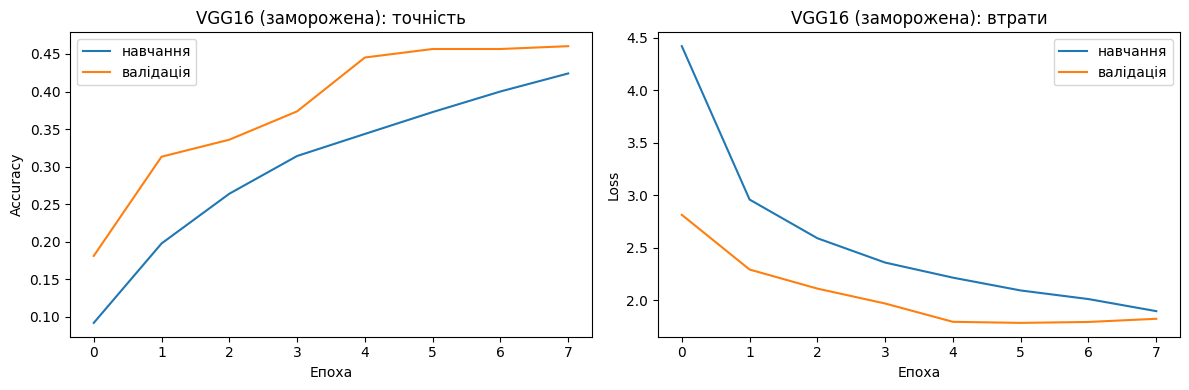

In [13]:
early_stop_vgg = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

keras.backend.clear_session()
vgg_model, vgg_base = build_vgg(best_vgg[0], 0.4, best_vgg[1])

vgg_history1 = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stop_vgg],
    verbose=2
)

plot_history(vgg_history1, 'VGG16 (заморожена)')

### 13. Донавчання останнього блока VGG16

Epoch 1/8
239/239 - 18s - 74ms/step - accuracy: 0.4293 - loss: 1.8608 - val_accuracy: 0.4868 - val_loss: 1.5791
Epoch 2/8
239/239 - 14s - 60ms/step - accuracy: 0.4767 - loss: 1.6955 - val_accuracy: 0.5321 - val_loss: 1.4440
Epoch 3/8
239/239 - 14s - 60ms/step - accuracy: 0.5049 - loss: 1.5917 - val_accuracy: 0.5585 - val_loss: 1.3623
Epoch 4/8
239/239 - 14s - 60ms/step - accuracy: 0.5298 - loss: 1.5107 - val_accuracy: 0.5585 - val_loss: 1.3005
Epoch 5/8
239/239 - 14s - 60ms/step - accuracy: 0.5557 - loss: 1.4175 - val_accuracy: 0.5774 - val_loss: 1.2528
Epoch 6/8
239/239 - 14s - 60ms/step - accuracy: 0.5731 - loss: 1.3594 - val_accuracy: 0.6491 - val_loss: 1.1396
Epoch 7/8
239/239 - 14s - 60ms/step - accuracy: 0.5967 - loss: 1.2657 - val_accuracy: 0.6226 - val_loss: 1.1185
Epoch 8/8
239/239 - 14s - 60ms/step - accuracy: 0.6019 - loss: 1.2406 - val_accuracy: 0.6528 - val_loss: 1.0827


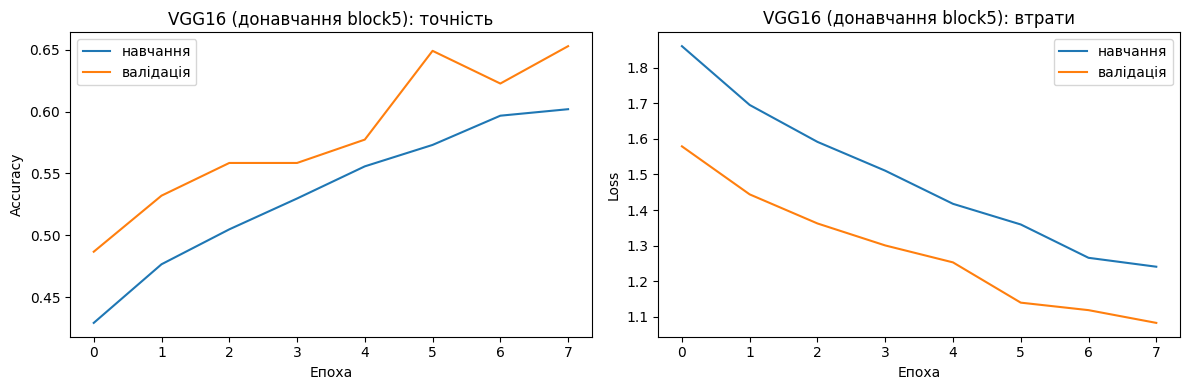

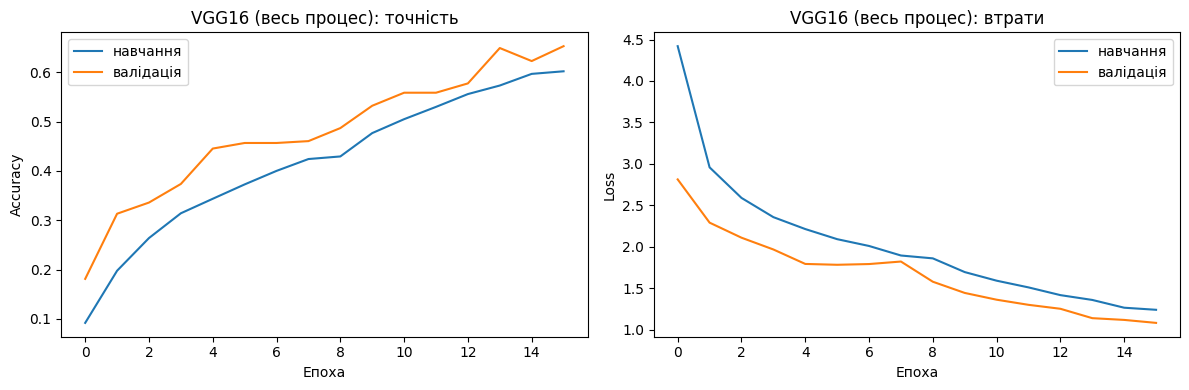

In [14]:
vgg_base.trainable = True
for layer in vgg_base.layers:
    layer.trainable = layer.name.startswith('block5')

vgg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_ft = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

vgg_history2 = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stop_ft],
    verbose=2
)

plot_history(vgg_history2, 'VGG16 (донавчання block5)')

full_history = {}
for k in vgg_history1.history:
    full_history[k] = vgg_history1.history[k] + vgg_history2.history[k]

plot_history(full_history, 'VGG16 (весь процес)')

## Частина 4. Оцінка та візуалізація результатів

### 14. Порівняння моделей на тестовій вибірці

In [15]:
cnn_loss, cnn_acc = cnn_model.evaluate(test_ds, verbose=0)
vgg_loss, vgg_acc = vgg_model.evaluate(test_ds, verbose=0)

table = pd.DataFrame({
    'Модель': ['Згорткова', 'VGG16 (донавчання)'],
    'Точність на тесті': [round(cnn_acc, 4), round(vgg_acc, 4)],
    'Втрати на тесті': [round(cnn_loss, 4), round(vgg_loss, 4)]
})
print(table)

               Модель  Точність на тесті  Втрати на тесті
0           Згорткова             0.5283           1.7515
1  VGG16 (донавчання)             0.5811           1.4108


### 15. Візуалізація класифікації

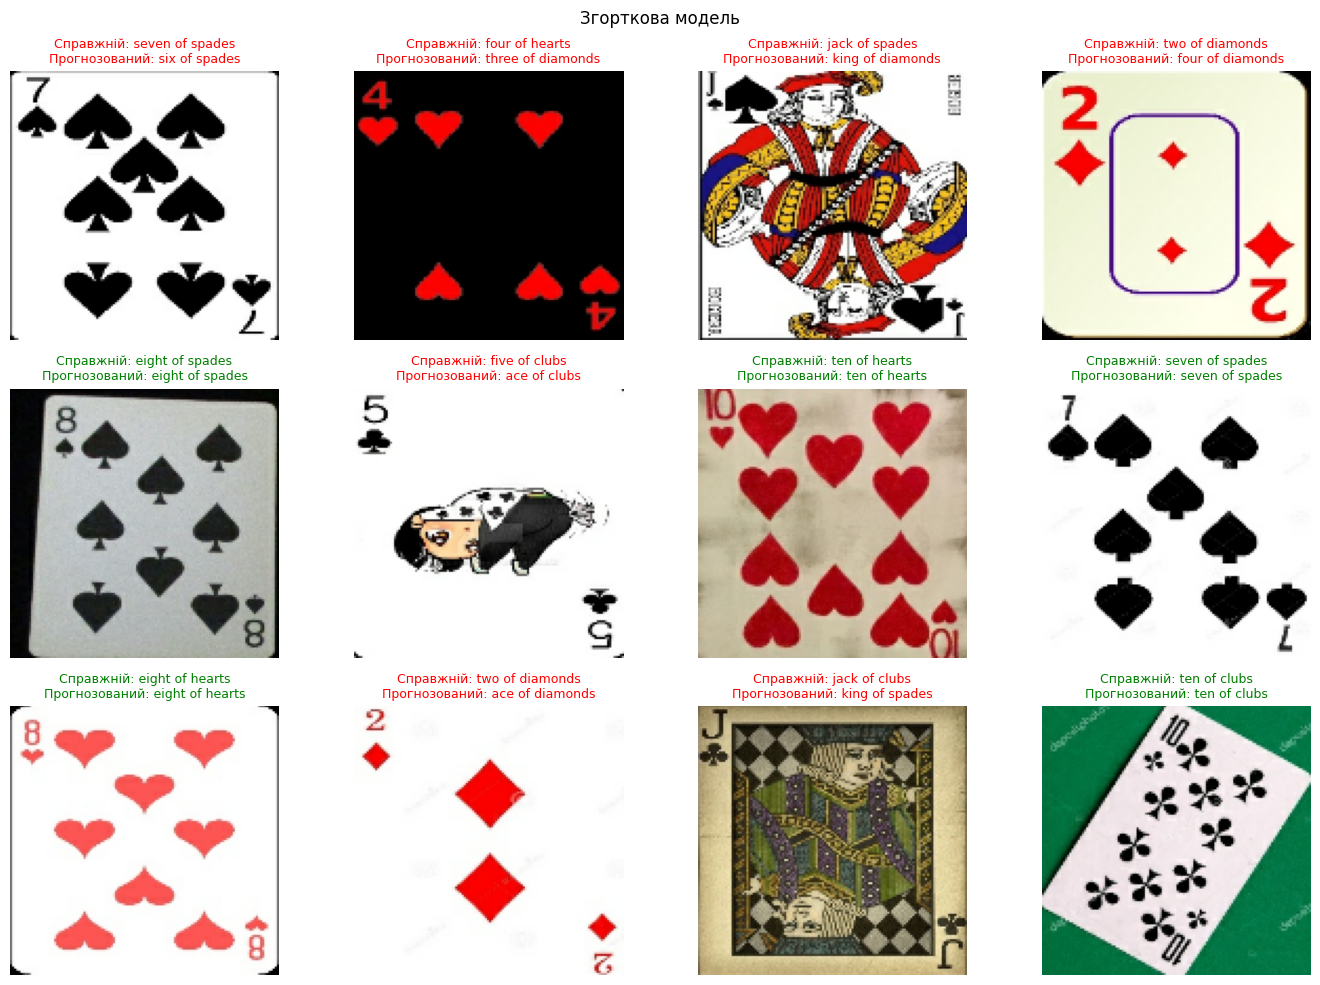

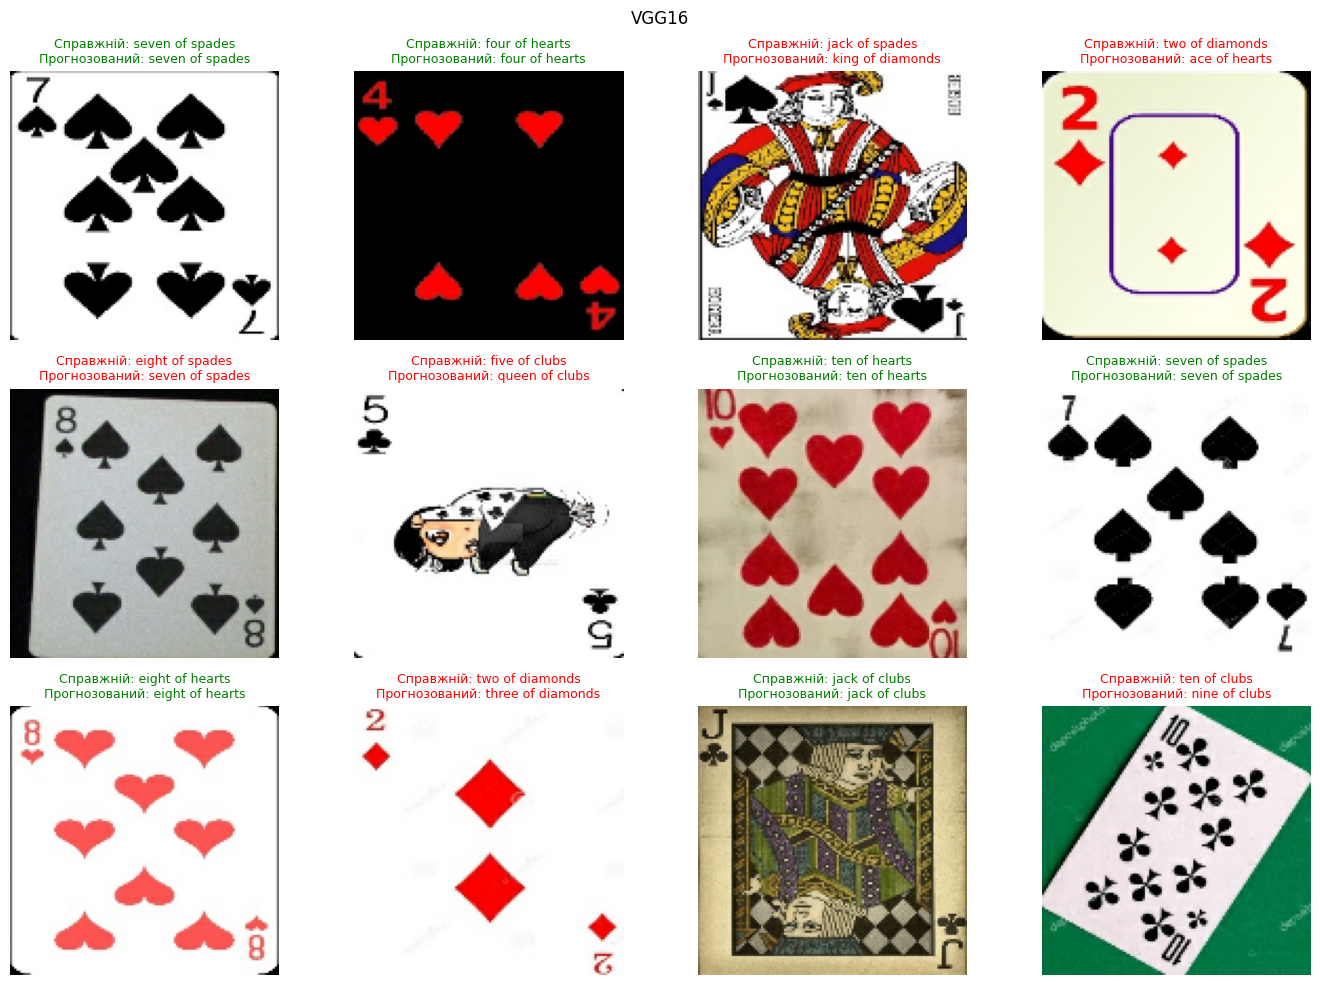

In [16]:
def show_predictions(model, name, n=12):
    vis_ds = test_ds.unbatch().shuffle(300, seed=3).batch(n).take(1)
    for images, labels in vis_ds:
        probs = model.predict(images, verbose=0)
        preds = np.argmax(probs, axis=1)

        plt.figure(figsize=(14, 10))
        for i in range(n):
            plt.subplot(3, 4, i + 1)
            plt.imshow(images[i].numpy().astype('uint8'))
            true_name = class_names[labels[i]]
            pred_name = class_names[preds[i]]
            color = 'green' if preds[i] == labels[i].numpy() else 'red'
            plt.title('Справжній: ' + true_name + '\nПрогнозований: ' + pred_name, color=color, fontsize=9)
            plt.axis('off')
        plt.suptitle(name)
        plt.tight_layout()
        plt.show()

show_predictions(cnn_model, 'Згорткова модель')
show_predictions(vgg_model, 'VGG16')

### 16. Аналіз помилок

In [17]:
y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_pred = np.argmax(vgg_model.predict(test_ds, verbose=0), axis=1)

wrong = np.where(y_true != y_pred)[0]
print('Помилок у VGG16:', len(wrong), 'з', len(y_true))
for i in wrong:
    print('справжній:', class_names[y_true[i]], ' прогнозований:', class_names[y_pred[i]])

Помилок у VGG16: 111 з 265
справжній: ace of clubs  прогнозований: ace of spades
справжній: eight of clubs  прогнозований: seven of clubs
справжній: eight of diamonds  прогнозований: ten of diamonds
справжній: eight of hearts  прогнозований: six of hearts
справжній: eight of spades  прогнозований: seven of spades
справжній: eight of spades  прогнозований: nine of spades
справжній: eight of spades  прогнозований: seven of spades
справжній: eight of spades  прогнозований: six of clubs
справжній: eight of spades  прогнозований: six of spades
справжній: five of clubs  прогнозований: four of clubs
справжній: five of clubs  прогнозований: queen of clubs
справжній: five of clubs  прогнозований: four of clubs
справжній: five of clubs  прогнозований: four of clubs
справжній: five of diamonds  прогнозований: seven of diamonds
справжній: five of diamonds  прогнозований: ace of diamonds
справжній: five of hearts  прогнозований: five of spades
справжній: five of hearts  прогнозований: nine of heart

## Висновки

1. Я виконала класифікацію зображень гральних карт (53 класи). Класи майже збалансовані, тому спеціальної боротьби з дисбалансом не знадобилося. Підготовка даних полягала в зменшенні зображень до 128x128, масштабуванні пікселів та легкій аугментації (поворот, зум, контраст).

2. Власна згорткова модель із чотирьох блоків показала точність на тесті 52.8% (втрати 1.75). За 15 епох точність на валідації зросла з 1.9% до 63.0%. Точність на навчанні (54.5%) нижча, ніж на валідації, тобто перенавчання немає: модель швидше недонавчена і могла б покращитись при більшій кількості епох.

3. Модель VGG16 з попередньо навченими вагами показала точність на тесті 58.1% (втрати 1.41), тобто на 5.3 відсоткових пункти краще за згорткову модель. Після навчання лише верхніх шарів точність на валідації була близько 46%, а після донавчання блока block5 з малим learning rate (1e-5) зросла до 65.3%, а втрати зменшились з 1.58 до 1.08. Отже, донавчання останнього блока дало помітне покращення.

4. Підбір параметрів: для згорткової моделі найкращими виявились learning rate 3e-4 та dropout 0.3, для VGG16 learning rate 1e-3 та 256 нейронів у повнозв'язному шарі. Через обмеження часу в Colab кожну комбінацію я навчала лише 2 епохи, тому результати підбору не дуже надійні. Наприклад, для VGG16 менший learning rate 1e-4 за 2 епохи не встиг навчитися, хоча при довшому навчанні він міг би виявитись кращим.

5. Рання зупинка при навчанні верхніх шарів VGG16 повернула ваги з 6-ї епохи, де val_loss був найменшим (1.78), бо далі він почав зростати. Для згорткової моделі (15 епох) і для донавчання block5 (8 епох) val_loss зменшувався майже до кінця, тому зупинка не спрацювала, і навчання можна було б продовжити.

6. VGG16 помилилась у 111 випадках із 265 зображень тесту. Найчастіше модель плутає схожі карти: у 66 помилках масть визначена правильно, але номінал сусідній (наприклад, seven of diamonds і eight of diamonds, ten of diamonds і nine of diamonds), а також карти однакового номіналу, але різної масті (queen of diamonds і queen of hearts). Це пов'язано з тим, що після зменшення до 128x128 дрібні значки на картах гірше видно. Також є помилки на джокері.

7. Загалом VGG16 з перенесенням навчання працює краще за власну згорткову модель, але різниця невелика, бо обидві моделі навчались мало. Для прискорення роботи я використала зменшені зображення та невелику кількість епох, тому з розміром 224x224 та більшою кількістю епох точність, особливо в VGG16, могла б бути помітно вищою.